# Actividad 1 · Ciclo de vida del conocimiento en Softtek
**Gael Rodríguez Jiménez · AL03109273**
Sistemas y tecnologías de administración del conocimiento · Universidad Tecmilenio

Este notebook genera el **diagrama del ciclo de vida del conocimiento** de la actividad y tres **gráficas** que lo complementan:

1. **Diagrama del ciclo**: las 5 etapas, los flujos entre áreas, el conocimiento tácito y explícito, y los puntos donde interviene la IA.
2. **Mapa de calor**: qué áreas participan en cada etapa.
3. **Diagrama de Sankey (interactivo)**: cómo viaja el conocimiento entre áreas, separando lo tácito de lo explícito.
4. **Matriz de IA por etapa**: en qué etapa apoya cada función de inteligencia artificial.

> El caso es ilustrativo: los datos salen del análisis que hicimos en el documento, no de información interna de Softtek.

Para correrlo: **Entorno de ejecución → Ejecutar todas** (o `Ctrl + F9`).

## 0. Librerías y colores
Todo lo que usamos ya viene instalado en Colab: **matplotlib** para el diagrama y el mapa de calor, **numpy** para las matrices y **plotly** para el Sankey interactivo.

In [1]:
import textwrap                       # para partir textos largos en varias líneas
import numpy as np                    # para manejar las matrices de las gráficas
import matplotlib.pyplot as plt       # para dibujar el diagrama y las gráficas estáticas
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch  # figuras: recuadros, círculo y flechas
import plotly.graph_objects as go     # para el diagrama de Sankey interactivo

# Paleta de colores que usamos en todo el notebook (la misma del documento)
VERDE = "#0B5D51"                     # color principal: etapas y flujos
TAC, TACB = "#FBE9DC", "#C0611B"      # conocimiento tácito: relleno naranja claro y borde naranja
EXP, EXPB = "#E1EBF7", "#2457A0"      # conocimiento explícito: relleno azul claro y borde azul
IA, IAB = "#EEE3F5", "#6B3FA0"        # intervención de IA: relleno morado claro y borde morado

# Nombres cortos de las 5 etapas; los reutilizamos en todas las gráficas
ETAPAS = ["1. Creación\ny captura", "2. Almacenamiento\ny organización", "3. Compartir\ny transferir",
          "4. Aplicación", "5. Actualización y\nretroalimentación"]
print("Librerías cargadas ✔")

Librerías cargadas ✔


## 1. Diagrama del ciclo de vida del conocimiento
Primero definimos cuatro funciones de dibujo y después las usamos para armar el diagrama.

- `etapa(...)` dibuja un recuadro de etapa con su título, las áreas que participan y dos cajitas: **tácito** (naranja) y **explícito** (azul).
- `ia(...)` dibuja una tarjeta morada con un punto donde interviene la IA.
- `flecha(...)` dibuja una flecha gruesa curva: es un **flujo de conocimiento entre áreas**.
- `punteada(...)` dibuja una flecha punteada: es la conexión de cada etapa con el repositorio o de la IA con una etapa.

El lienzo mide 2000 × 1360 "unidades", así que las posiciones (x, y) se leen como coordenadas dentro de ese rectángulo; el eje y va hacia abajo, como en una hoja.

In [2]:
def w(texto, n):
    """Parte un texto en renglones de máximo n caracteres."""
    return "\n".join(textwrap.wrap(texto, n))      # textwrap corta por palabras y unimos con saltos de línea

def etapa(ax, x, y, num, titulo, areas, tacito, explicito, ancho=560, alto=300):
    """Dibuja el recuadro de una etapa del ciclo."""
    # Recuadro blanco con borde verde (el cuerpo de la etapa)
    ax.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0,rounding_size=14", fc="white", ec=VERDE, lw=3))
    # Franja verde superior donde va el título
    ax.add_patch(FancyBboxPatch((x, y), ancho, 56, boxstyle="round,pad=0,rounding_size=14", fc=VERDE, ec=VERDE, lw=3))
    # Circulito blanco con el número de la etapa
    ax.add_patch(Circle((x + 40, y + 28), 20, fc="white", ec="none"))
    ax.text(x + 40, y + 29, num, ha="center", va="center", fontsize=17, weight="bold", color=VERDE)
    # Título en blanco; si es muy largo usamos una letra un poco más chica para que quepa
    ax.text(x + 76, y + 29, titulo, va="center", fontsize=19 if len(titulo) < 30 else 16.5, weight="bold", color="white")
    # Renglón en cursiva con las áreas que participan
    ax.text(x + 28, y + 78, "Áreas: " + areas, va="center", fontsize=11.5, style="italic", color="#555")
    # Dos cajitas: primero la de conocimiento tácito y debajo la de explícito
    for i, (etiqueta, texto, relleno, borde) in enumerate([("TÁCITO", tacito, TAC, TACB), ("EXPLÍCITO", explicito, EXP, EXPB)]):
        yy = y + 98 + i * 92                          # la segunda cajita va 92 unidades más abajo
        ax.add_patch(FancyBboxPatch((x + 30, yy), ancho - 60, 78, boxstyle="round,pad=0,rounding_size=8", fc=relleno, ec=borde, lw=1.8))
        ax.text(x + 44, yy + 16, etiqueta, fontsize=12.5, weight="bold", color=borde, va="center")  # "TÁCITO" / "EXPLÍCITO"
        ax.text(x + 44, yy + 30, w(texto, 54), fontsize=12, va="top", color="#222", linespacing=1.4)  # el ejemplo

def ia(ax, x, y, etiqueta, titulo, texto, ancho=400):
    """Dibuja una tarjeta morada de intervención de IA."""
    ax.add_patch(FancyBboxPatch((x, y), ancho, 120, boxstyle="round,pad=0,rounding_size=12", fc=IA, ec=IAB, lw=2.2))  # tarjeta
    ax.add_patch(FancyBboxPatch((x + 12, y + 12), 74, 30, boxstyle="round,pad=0,rounding_size=8", fc=IAB, ec="none"))  # etiqueta "IA n"
    ax.text(x + 49, y + 27, etiqueta, ha="center", va="center", fontsize=12.5, weight="bold", color="white")
    ax.text(x + 98, y + 27, titulo, va="center", fontsize=13.5, weight="bold", color=IAB)        # nombre de la función
    ax.text(x + 16, y + 52, w(texto, 43), va="top", fontsize=11.5, color="#222", linespacing=1.4)  # qué hace

def flecha(ax, a, b, curva, texto=None, pos=None):
    """Flecha gruesa verde (flujo entre áreas). curva > 0 dobla a un lado y < 0 al otro."""
    ax.add_patch(FancyArrowPatch(a, b, connectionstyle=f"arc3,rad={curva}", arrowstyle="-|>,head_length=18,head_width=10",
                                 lw=4, color=VERDE, mutation_scale=1.4))
    if texto:                                          # si la flecha lleva leyenda, la escribimos en pos
        ax.text(*pos, texto, ha="center", va="center", fontsize=13, weight="bold", color=VERDE, linespacing=1.3)

def punteada(ax, a, b, color="#666", grosor=1.6):
    """Flecha punteada delgada (conexión con el repositorio o con la IA)."""
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>,head_length=8,head_width=4", linestyle=(0, (3, 3)),
                                 lw=grosor, color=color, mutation_scale=1.5))
print("Funciones de dibujo listas ✔")

Funciones de dibujo listas ✔


Ahora sí armamos el diagrama. El orden del código sigue el orden en que se "lee" la figura:
título → las 5 etapas en círculo → el repositorio al centro → flechas del ciclo → tarjetas de IA → leyenda.
Al final se guarda como `diagrama_ciclo_conocimiento_softtek.png` en alta resolución.

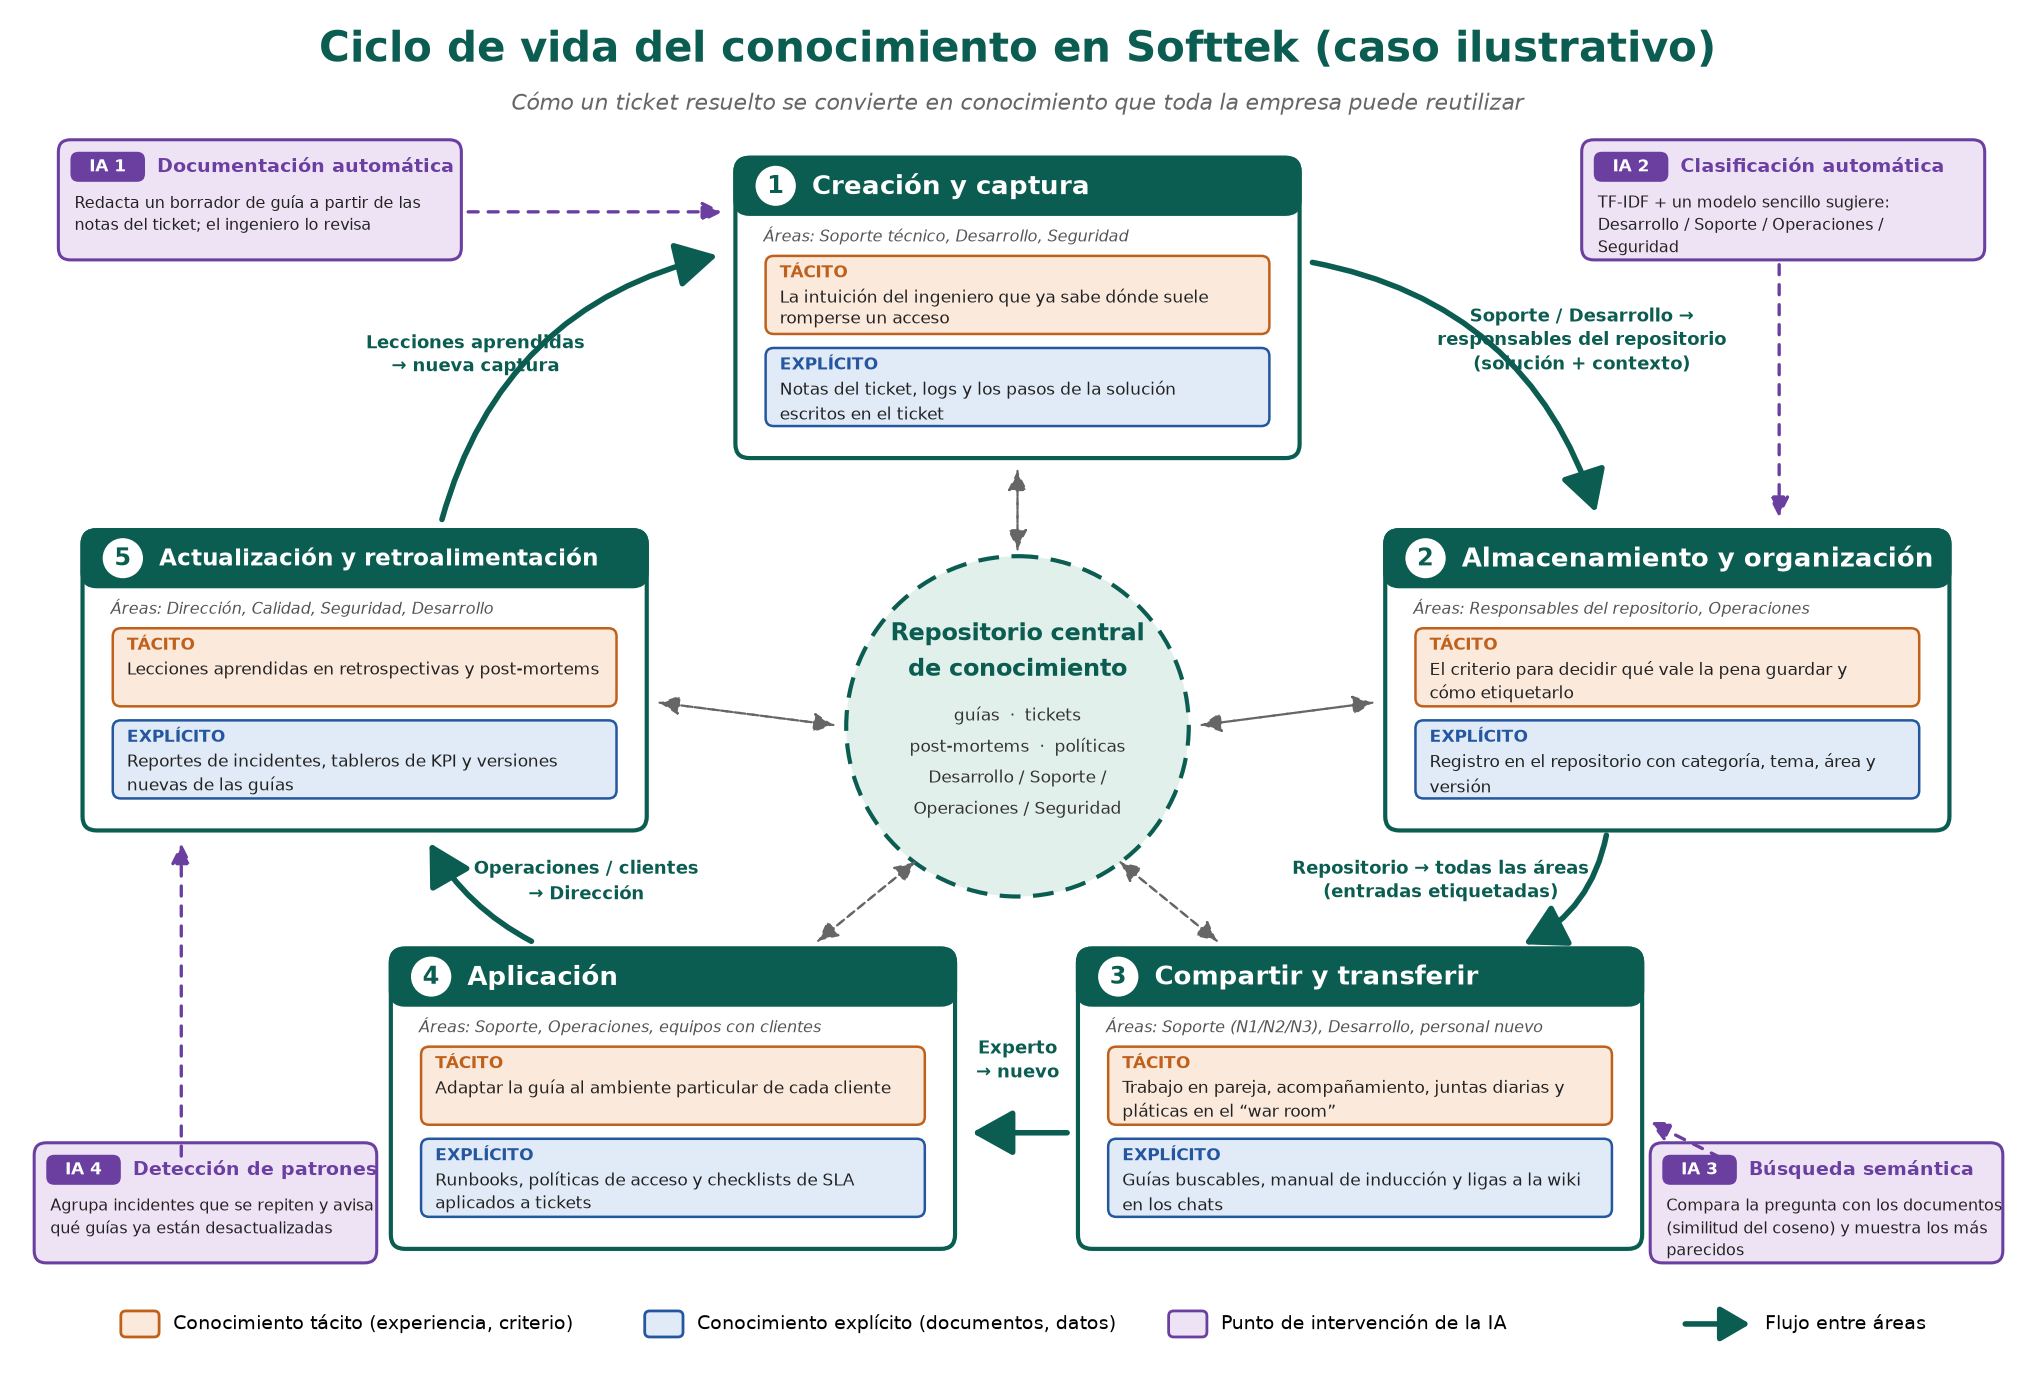

In [3]:
fig, ax = plt.subplots(figsize=(26, 17.68), dpi=100)   # lienzo grande para que el texto se lea bien
ax.set_xlim(0, 2000); ax.set_ylim(1360, 0)              # sistema de coordenadas (y hacia abajo)
ax.axis("off")                                          # sin ejes: es un diagrama, no una gráfica

# --- Título y subtítulo ---
ax.text(1000, 52, "Ciclo de vida del conocimiento en Softtek (caso ilustrativo)", ha="center", fontsize=30, weight="bold", color=VERDE)
ax.text(1000, 100, "Cómo un ticket resuelto se convierte en conocimiento que toda la empresa puede reutilizar",
        ha="center", fontsize=16, style="italic", color="#666")

# --- Las 5 etapas, acomodadas en círculo en el sentido de las manecillas del reloj ---
etapa(ax, 720, 148, "1", "Creación y captura", "Soporte técnico, Desarrollo, Seguridad",
      "La intuición del ingeniero que ya sabe dónde suele romperse un acceso",
      "Notas del ticket, logs y los pasos de la solución escritos en el ticket")
etapa(ax, 1365, 520, "2", "Almacenamiento y organización", "Responsables del repositorio, Operaciones",
      "El criterio para decidir qué vale la pena guardar y cómo etiquetarlo",
      "Registro en el repositorio con categoría, tema, área y versión")
etapa(ax, 1060, 938, "3", "Compartir y transferir", "Soporte (N1/N2/N3), Desarrollo, personal nuevo",
      "Trabajo en pareja, acompañamiento, juntas diarias y pláticas en el “war room”",
      "Guías buscables, manual de inducción y ligas a la wiki en los chats")
etapa(ax, 378, 938, "4", "Aplicación", "Soporte, Operaciones, equipos con clientes",
      "Adaptar la guía al ambiente particular de cada cliente",
      "Runbooks, políticas de acceso y checklists de SLA aplicados a tickets")
etapa(ax, 72, 520, "5", "Actualización y retroalimentación", "Dirección, Calidad, Seguridad, Desarrollo",
      "Lecciones aprendidas en retrospectivas y post-mortems",
      "Reportes de incidentes, tableros de KPI y versiones nuevas de las guías")

# --- Repositorio central: círculo punteado al que se conectan todas las etapas ---
ax.add_patch(Circle((1000, 716), 170, fc="#E2F0EC", ec=VERDE, lw=3, linestyle=(0, (5, 3))))
ax.text(1000, 640, "Repositorio central\nde conocimiento", ha="center", va="center", fontsize=17, weight="bold", color=VERDE, linespacing=1.4)
ax.text(1000, 752, "guías  ·  tickets\npost-mortems  ·  políticas\nDesarrollo / Soporte /\nOperaciones / Seguridad",
        ha="center", va="center", fontsize=12.5, color="#333", linespacing=1.8)

# --- Flechas del ciclo: cada una dice qué área le pasa conocimiento a cuál ---
flecha(ax, (1290, 252), (1575, 505), -0.3, "Soporte / Desarrollo →\nresponsables del repositorio\n(solución + contexto)", (1560, 330))
flecha(ax, (1585, 822), (1500, 935), -0.25, "Repositorio → todas las áreas\n(entradas etiquetadas)", (1420, 870))
flecha(ax, (1052, 1122), (952, 1122), 0, "Experto\n→ nuevo", (1000, 1050))
flecha(ax, (520, 932), (415, 830), -0.15, "Operaciones / clientes\n→ Dirección", (572, 870))
flecha(ax, (428, 512), (705, 245), -0.3, "Lecciones aprendidas\n→ nueva captura", (462, 345))

# --- Conexiones de ida y vuelta entre cada etapa y el repositorio ---
for a, b in [((1000, 458), (1000, 542)), ((1355, 692), (1180, 715)), ((1200, 932), (1100, 850)),
             ((800, 932), (900, 850)), ((820, 715), (642, 692))]:
    punteada(ax, a, b); punteada(ax, b, a)              # dos flechas = el conocimiento entra y sale

# --- Puntos de intervención de la IA, cada uno conectado a su etapa ---
ia(ax, 48, 130, "IA 1", "Documentación automática", "Redacta un borrador de guía a partir de las notas del ticket; el ingeniero lo revisa")
punteada(ax, (452, 202), (710, 202), IAB, 2.4)          # → Etapa 1
ia(ax, 1560, 130, "IA 2", "Clasificación automática", "TF-IDF + un modelo sencillo sugiere: Desarrollo / Soporte / Operaciones / Seguridad")
punteada(ax, (1756, 252), (1756, 510), IAB, 2.4)        # → Etapa 2
ia(ax, 1628, 1132, "IA 3", "Búsqueda semántica", "Compara la pregunta con los documentos (similitud del coseno) y muestra los más parecidos", ancho=350)
punteada(ax, (1700, 1148), (1625, 1110), IAB, 2.4)      # → Etapa 3
ia(ax, 24, 1132, "IA 4", "Detección de patrones", "Agrupa incidentes que se repiten y avisa qué guías ya están desactualizadas", ancho=340)
punteada(ax, (170, 1148), (170, 830), IAB, 2.4)         # → Etapa 5

# --- Leyenda en la parte de abajo ---
leyenda = [(TAC, TACB, "Conocimiento tácito (experiencia, criterio)"),
           (EXP, EXPB, "Conocimiento explícito (documentos, datos)"),
           (IA, IAB, "Punto de intervención de la IA")]
for i, (relleno, borde, texto) in enumerate(leyenda):
    x = 110 + i * 520                                   # separamos cada elemento 520 unidades
    ax.add_patch(FancyBboxPatch((x, 1300), 38, 26, boxstyle="round,pad=0,rounding_size=5", fc=relleno, ec=borde, lw=2))
    ax.text(x + 52, 1313, texto, va="center", fontsize=14)
ax.add_patch(FancyArrowPatch((1660, 1313), (1730, 1313), arrowstyle="-|>,head_length=12,head_width=7", lw=4, color=VERDE, mutation_scale=1.5))
ax.text(1742, 1313, "Flujo entre áreas", va="center", fontsize=14)

plt.savefig("diagrama_ciclo_conocimiento_softtek.png", bbox_inches="tight", facecolor="white", dpi=150)  # imagen para el Word
plt.show()                                              # lo mostramos aquí en Colab

## 2. Mapa de calor: áreas que participan en cada etapa
Cada celda dice qué tan involucrada está un área en una etapa, según el análisis de la sección 4 del documento:

- **2 = área principal** (es la que hace el trabajo de esa etapa)
- **1 = participa** (aporta o recibe conocimiento)
- **0 = no participa** en nuestro caso

Así se ve de un vistazo que **Soporte** está en todo el ciclo, mientras que **Dirección y Calidad** aparecen sobre todo al final, cuando se toman decisiones.

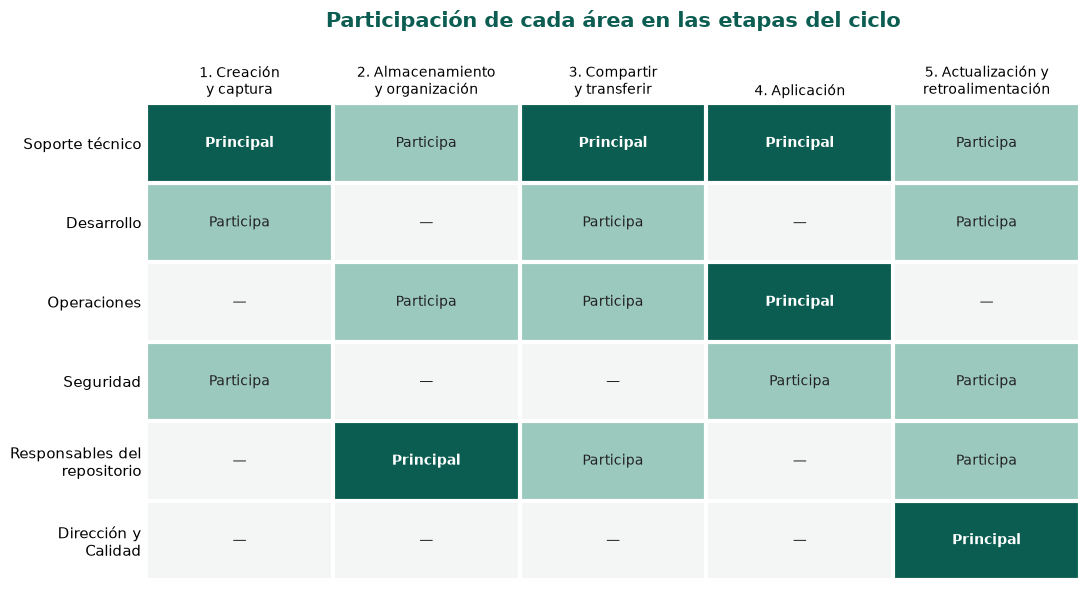

Soporte técnico                  aparece en 5 de 5 etapas
Desarrollo                       aparece en 3 de 5 etapas
Operaciones                      aparece en 3 de 5 etapas
Seguridad                        aparece en 3 de 5 etapas
Responsables del repositorio     aparece en 3 de 5 etapas
Dirección y Calidad              aparece en 1 de 5 etapas


In [4]:
AREAS = ["Soporte técnico", "Desarrollo", "Operaciones", "Seguridad", "Responsables del\nrepositorio", "Dirección y\nCalidad"]

# Filas = áreas, columnas = etapas 1 a 5 (valores tomados del análisis del documento)
participacion = np.array([
    #E1 E2 E3 E4 E5
    [2, 1, 2, 2, 1],   # Soporte técnico: resuelve, documenta, enseña y aplica
    [1, 0, 1, 0, 1],   # Desarrollo: ayuda a diagnosticar, comparte y corrige el módulo
    [0, 1, 1, 2, 0],   # Operaciones: guarda runbooks y los aplica
    [1, 0, 0, 1, 1],   # Seguridad: valida accesos, aplica y actualiza la política
    [0, 2, 1, 0, 1],   # Responsables del repositorio: ordenan y publican
    [0, 0, 0, 0, 2],   # Dirección y Calidad: revisan indicadores y deciden
])

from matplotlib.colors import ListedColormap               # para hacer una escala de 3 colores fija
colores = ListedColormap(["#F4F6F5", "#9CC9BE", VERDE])    # 0 = gris claro, 1 = verde medio, 2 = verde fuerte

fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(participacion, cmap=colores, vmin=0, vmax=2, aspect="auto")   # dibuja la matriz como mapa de calor
ax.set_xticks(range(5), ETAPAS, fontsize=10)               # nombres de las etapas abajo
ax.set_yticks(range(len(AREAS)), AREAS, fontsize=10.5)     # nombres de las áreas a la izquierda
ax.xaxis.tick_top()                                        # pasamos las etiquetas de etapas arriba para leer mejor

textos = {0: "—", 1: "Participa", 2: "Principal"}          # qué escribir dentro de cada celda
for i in range(participacion.shape[0]):                    # recorremos filas (áreas)
    for j in range(participacion.shape[1]):                # y columnas (etapas)
        v = participacion[i, j]
        ax.text(j, i, textos[v], ha="center", va="center", fontsize=10,
                color="white" if v == 2 else "#222", weight="bold" if v == 2 else "normal")

ax.set_xticks(np.arange(-.5, 5), minor=True); ax.set_yticks(np.arange(-.5, len(AREAS)), minor=True)
ax.grid(which="minor", color="white", linewidth=3)         # líneas blancas para separar las celdas
ax.tick_params(which="both", length=0)                     # quitamos las rayitas de los ejes
for borde in ax.spines.values(): borde.set_visible(False)  # y el marco
ax.set_title("Participación de cada área en las etapas del ciclo", fontsize=15, weight="bold", color=VERDE, pad=55)

plt.tight_layout()
plt.savefig("mapa_calor_areas_etapas.png", dpi=150, facecolor="white")
plt.show()

# Un pequeño resumen numérico: en cuántas etapas aparece cada área
for area, fila in zip(AREAS, participacion):
    print(f"{area.replace(chr(10), ' '):32s} aparece en {np.count_nonzero(fila)} de 5 etapas")

## 3. Sankey: cómo viaja el conocimiento entre áreas
Un diagrama de Sankey muestra **flujos**: cada banda va de un área origen a un área destino y su grosor indica **cuántos conocimientos distintos** pasan por ese camino en nuestro caso del ticket de acceso.

El color de la banda indica el **tipo de conocimiento**: 🟧 naranja = tácito, 🟦 azul = explícito.
Es **interactivo**: si pasas el mouse sobre una banda, Colab te dice qué conocimiento es.

Las correcciones y la política nueva llegan a un nodo final, **"Repositorio actualizado"**, en lugar de regresar al inicio: así el diagrama se lee de izquierda a derecha y se ve que el ciclo se cierra y vuelve a empezar en la etapa 1.

In [5]:
# Cada flujo: (área origen, área destino, conocimiento que se pasa, tipo)
flujos = [
    ("Soporte N2 (experta)", "Repositorio central", "Guía con síntoma, causa y solución", "Explícito"),
    ("Soporte N2 (experta)", "Repositorio central", "Notas y logs del ticket", "Explícito"),
    ("Soporte N2 (experta)", "Soporte N1 / personal nuevo", "Forma de razonar el diagnóstico (junta diaria)", "Tácito"),
    ("Soporte N2 (experta)", "Soporte N1 / personal nuevo", "Acompañamiento en pareja", "Tácito"),
    ("Soporte N2 (experta)", "Desarrollo", "Reporte del error en el módulo de acceso", "Explícito"),
    ("Soporte N2 (experta)", "Dirección y Calidad", "Lecciones aprendidas en la retrospectiva", "Tácito"),
    ("Desarrollo", "Repositorio central", "Nota técnica del cambio en el módulo", "Explícito"),
    ("Repositorio central", "Soporte N1 / personal nuevo", "Guía encontrada con el buscador", "Explícito"),
    ("Repositorio central", "Operaciones", "Procedimiento para el runbook", "Explícito"),
    ("Soporte N1 / personal nuevo", "Clientes", "Solución adaptada al ambiente del cliente", "Tácito"),
    ("Soporte N1 / personal nuevo", "Repositorio actualizado (vuelve a la etapa 1)", "Corrección de un paso desactualizado", "Explícito"),
    ("Operaciones", "Dirección y Calidad", "Indicadores de tickets resueltos", "Explícito"),
    ("Dirección y Calidad", "Seguridad", "Decisión de cambiar la política de contraseñas", "Tácito"),
    ("Seguridad", "Repositorio actualizado (vuelve a la etapa 1)", "Política de rotación actualizada", "Explícito"),
]

# Juntamos los flujos que tienen mismo origen, destino y tipo para que formen una sola banda más gruesa
agrupados = {}
for origen, destino, que, tipo in flujos:
    clave = (origen, destino, tipo)
    agrupados.setdefault(clave, []).append(que)            # guardamos la lista de conocimientos de esa banda

# Plotly necesita que cada área sea un número (índice), así que hacemos la lista de nodos
nodos = list(dict.fromkeys([f[0] for f in flujos] + [f[1] for f in flujos]))   # áreas sin repetir, en orden
indice = {nombre: i for i, nombre in enumerate(nodos)}

color_banda = {"Tácito": "rgba(192,97,27,0.45)", "Explícito": "rgba(36,87,160,0.45)"}   # naranja / azul transparentes
color_nodo = [IAB if n.startswith("Repositorio") else VERDE for n in nodos]              # el repositorio va en morado

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(label=nodos, color=color_nodo, pad=22, thickness=22,
              line=dict(color="white", width=1)),
    link=dict(
        source=[indice[o] for (o, d, t) in agrupados],          # de dónde sale cada banda
        target=[indice[d] for (o, d, t) in agrupados],          # a dónde llega
        value=[len(v) for v in agrupados.values()],             # grosor = número de conocimientos
        color=[color_banda[t] for (o, d, t) in agrupados],      # color según tácito / explícito
        customdata=[f"<b>{t}</b><br>" + "<br>".join("• " + x for x in v) for (o, d, t), v in agrupados.items()],
        hovertemplate="%{source.label} → %{target.label}<br>%{customdata}<extra></extra>",  # texto al pasar el mouse
    ),
))
fig.update_layout(
    title=dict(text="Flujo de conocimiento entre áreas (caso del ticket de acceso)<br>"
                    "<sup><span style='color:#C0611B'>■ tácito</span>   <span style='color:#2457A0'>■ explícito</span>"
                    "   · grosor = número de conocimientos que pasan</sup>", font=dict(size=18, color=VERDE)),
    font=dict(size=13), height=560, margin=dict(l=20, r=20, t=90, b=20), paper_bgcolor="white",
)
fig.show()

# Conteo rápido de cuántos conocimientos de cada tipo circulan
tacitos = sum(1 for f in flujos if f[3] == "Tácito")
print(f"Conocimientos tácitos que circulan: {tacitos}  |  explícitos: {len(flujos) - tacitos}")

Conocimientos tácitos que circulan: 5  |  explícitos: 9


## 4. Matriz: en qué etapa apoya cada función de IA
Cada punto morado indica que esa función de inteligencia artificial apoya esa etapa (sección 6 del documento).
Las dos primeras (**clasificación** y **búsqueda semántica**) son las que vamos a programar en el prototipo del proyecto; por eso van marcadas con ★.

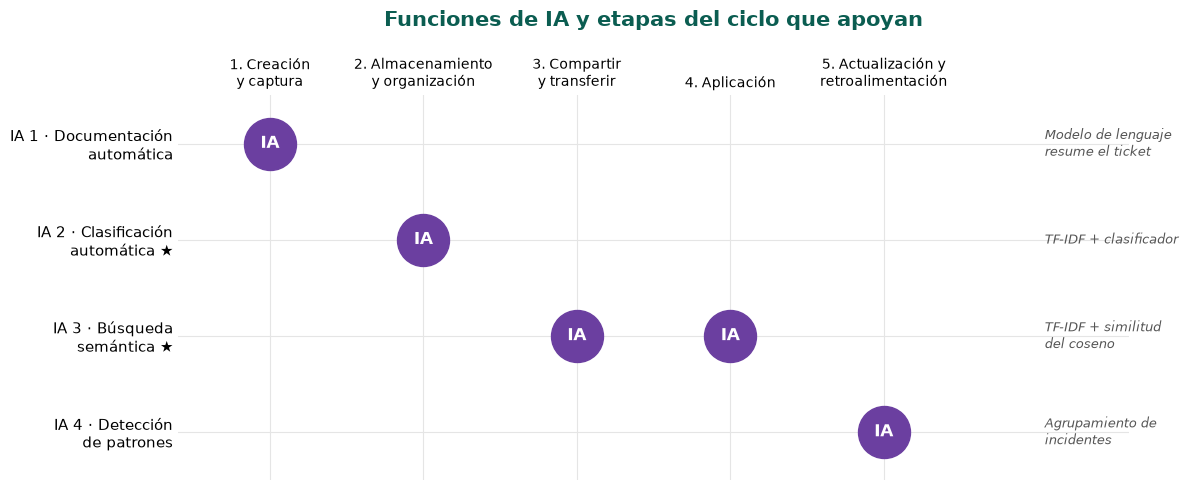

Etapas con apoyo de IA: 5 de 5


In [6]:
FUNCIONES_IA = ["IA 1 · Documentación\nautomática", "IA 2 · Clasificación\nautomática ★", "IA 3 · Búsqueda\nsemántica ★", "IA 4 · Detección\nde patrones"]
TECNICA = ["Modelo de lenguaje\nresume el ticket", "TF-IDF + clasificador", "TF-IDF + similitud\ndel coseno", "Agrupamiento de\nincidentes"]

# 1 = la función apoya esa etapa; filas = funciones de IA, columnas = etapas 1 a 5
apoyo = np.array([
    [1, 0, 0, 0, 0],   # Documentación automática → captura
    [0, 1, 0, 0, 0],   # Clasificación → almacenamiento
    [0, 0, 1, 1, 0],   # Búsqueda semántica → compartir y aplicar
    [0, 0, 0, 0, 1],   # Detección de patrones → actualización
])

fig, ax = plt.subplots(figsize=(12, 5))
filas, columnas = np.nonzero(apoyo)                         # posiciones donde hay un 1
ax.scatter(columnas, filas, s=1400, color=IAB, zorder=3)    # un círculo morado grande por cada apoyo
for f, c in zip(filas, columnas):
    ax.text(c, f, "IA", ha="center", va="center", color="white", weight="bold", fontsize=12, zorder=4)

ax.set_xticks(range(5), ETAPAS, fontsize=10)
ax.set_yticks(range(len(FUNCIONES_IA)), FUNCIONES_IA, fontsize=10.5)
ax.set_xlim(-0.6, 5.6); ax.set_ylim(len(FUNCIONES_IA) - 0.5, -0.5)   # dejamos espacio a la derecha para la técnica
ax.xaxis.tick_top()
for f, t in enumerate(TECNICA):                              # a la derecha escribimos la técnica de cada función
    ax.text(5.05, f, t, va="center", fontsize=9.5, color="#555", style="italic")
ax.grid(color="#E5E5E5", zorder=0)                           # cuadrícula suave para ubicar cada punto
ax.tick_params(length=0)
for borde in ax.spines.values(): borde.set_visible(False)
ax.set_title("Funciones de IA y etapas del ciclo que apoyan", fontsize=15, weight="bold", color=VERDE, pad=50)

plt.tight_layout()
plt.savefig("matriz_ia_etapas.png", dpi=150, facecolor="white")
plt.show()
print("Etapas con apoyo de IA:", np.count_nonzero(apoyo.sum(axis=0)), "de 5")

## 5. Descargar las imágenes
Esta celda descarga los PNG para pegarlos en el documento de Word. Solo funciona dentro de Colab.

In [7]:
try:
    from google.colab import files                         # módulo de Colab para descargar archivos
    for archivo in ["diagrama_ciclo_conocimiento_softtek.png", "mapa_calor_areas_etapas.png", "matriz_ia_etapas.png"]:
        files.download(archivo)                            # el navegador descarga cada imagen
except ImportError:
    print("No estás en Colab: las imágenes ya quedaron guardadas en la carpeta del notebook.")

No estás en Colab: las imágenes ya quedaron guardadas en la carpeta del notebook.
